# Extra: nuvem de palavras

Este é um notebook extra. Ele usa as notícias coletadas em [03-agencia-brasil.ipynb](03-agencia-brasil.ipynb). Se elas ainda não foram coletadas, este notebook roda o 03 do começo, o que leva uns 10 minutos.

Na nuvem de palavras, cada palavra aparece com tamanho proporcional à sua frequência. É um formato que chama atenção e aparece bastante em reportagens, mas tem limites, que vamos ver no fim.

In [1]:
import string
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer
from wordcloud import WordCloud

nltk.download('stopwords', quiet=True)

CSV = Path('../data/agencia-brasil.csv')
if not CSV.exists():
    # As notícias ainda não foram coletadas: roda o notebook 03 do começo
    %run 03-agencia-brasil.ipynb

news = pd.read_csv(CSV)

## Contando as palavras

Contamos as palavras como no notebook 03, com a mesma lista de stopwords.

A biblioteca `wordcloud` também sabe separar e contar palavras sozinha, mas com regras pensadas para o inglês. Por isso fazemos a contagem nós mesmos e entregamos só o resultado para ela.

In [2]:
tokenizer = RegexpTokenizer(r"\w+(?:[-']\w+)*")

# A mesma lista do notebook 03
news_stops = set(stopwords.words('portuguese')) | set(string.ascii_lowercase) | {
    'segundo', 'sobre', 'ainda', 'cada', 'ano', 'anos', 'desde', 'brasil', 'agência',
    'disse', 'afirmou', 'pode', 'ser', 'vai', 'após', 'além',
}


def count_words(texts, stops):
    counter = Counter()
    for text in texts:
        tokens = [token.lower() for token in tokenizer.tokenize(text)]
        counter.update(token for token in tokens if token not in stops and not token.isdigit())
    return counter

health = count_words(news.loc[news['editoria'] == 'saude', 'texto'], news_stops)
health.most_common(10)

[('saúde', 29),
 ('diabetes', 21),
 ('doença', 17),
 ('retinopatia', 16),
 ('diagnóstico', 14),
 ('diabética', 13),
 ('exame', 13),
 ('câncer', 12),
 ('cbo', 11),
 ('risco', 11)]

## A nuvem

Usamos uma cor só: se cada palavra tivesse uma cor diferente, o leitor poderia achar que as cores significam alguma coisa. O `random_state` fixa a posição das palavras, para que a nuvem saia igual toda vez que o notebook roda.

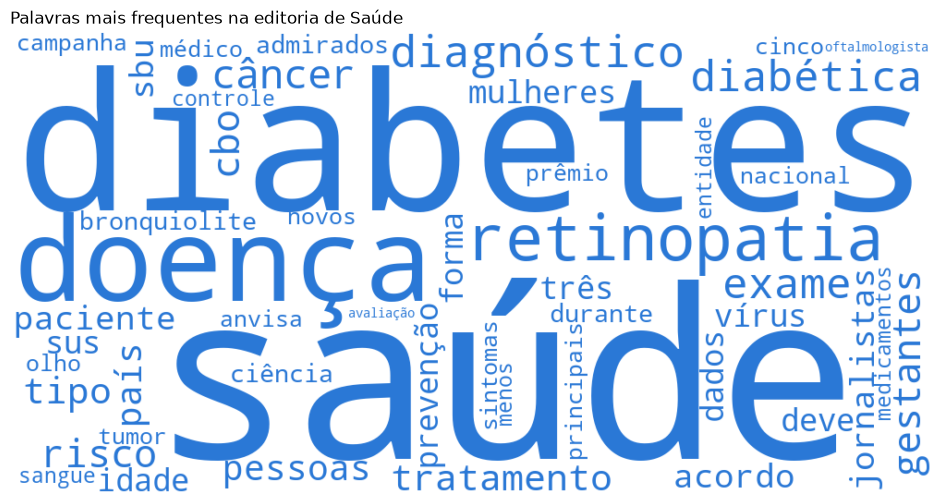

In [3]:
cloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    color_func=lambda *args, **kwargs: '#2a78d6',
    max_words=50,
    random_state=1,
).generate_from_frequencies(health)

plt.figure(figsize=(12, 6))
plt.imshow(cloud, interpolation='bilinear')
plt.axis('off')
plt.title('Palavras mais frequentes na editoria de Saúde', loc='left')
plt.show()

## Nuvem ou gráfico de barras?

Olhando só a nuvem, qual palavra aparece mais vezes: "saúde" ou "diabetes"? E quantas vezes a mais?

In [4]:
health['saúde'], health['diabetes']

(29, 21)

Na nuvem é difícil responder: o olho compara áreas mal, e palavras longas parecem maiores do que são, só por terem mais letras. Na coleta salva aqui, "diabetes" parece tão grande quanto "saúde", mas aparece menos vezes. No gráfico de barras do notebook 03, a resposta está no comprimento das barras.

Use a nuvem para chamar atenção para um tema, e o gráfico de barras quando o leitor precisa comparar.